<a href="https://colab.research.google.com/github/GIGAREHAN/Machine-learning-projects/blob/main/MinMaxScaleDEMO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wine Dataset Feature Scaling Demonstration

This notebook demonstrates the process of preparing and preprocessing the **Wine Dataset** using feature scaling, specifically focusing on **Min-Max Normalization** (scaling features to a range of $[0, 1]$).

## Dataset Overview
The dataset contains chemical analysis results of wines grown in a specific region in Italy. In this notebook, we focus on three main attributes:
1. **Class Label**: The target class (categorical indicator of the wine origin).
2. **Alcohol**: The alcohol content in the wine.
3. **Malic Acid**: The amount of malic acid present in the wine.

## Objectives
* Load and inspect the distribution of features (`Alcohol` and `Malic Acid`).
* Split the dataset into training and testing sets to prevent data leakage.
* Apply `MinMaxScaler` to normalize the numerical features.
* Visualize the distribution of features before and after scaling to analyze the transformation effect.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('wine_data.csv', header = None, usecols = [0,1,2])
df.columns = ['Class Label', 'Alcohol', 'Malic Acid']

In [3]:
df.head()

,Class Label,Alcohol,Malic Acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Class Label  178 non-null    int64  
 1   Alcohol      178 non-null    float64
 2   Malic Acid   178 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 4.3 KB


<Axes: xlabel='Alcohol', ylabel='Density'>

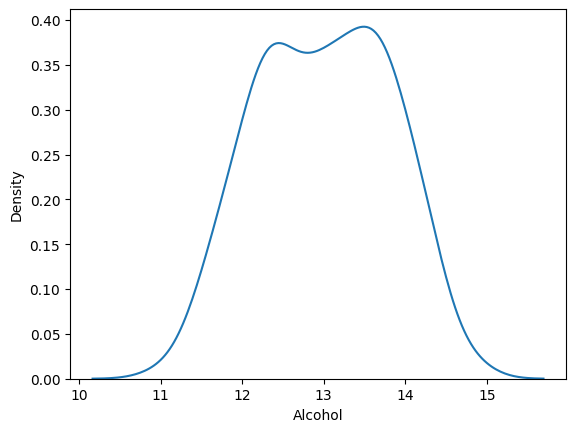

In [5]:
sns.kdeplot(df['Alcohol'])

<Axes: xlabel='Malic Acid', ylabel='Density'>

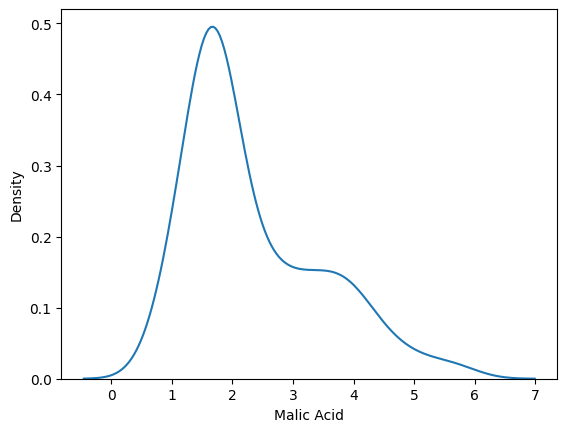

In [6]:
sns.kdeplot(df['Malic Acid'])

<Axes: xlabel='Alcohol', ylabel='Malic Acid'>

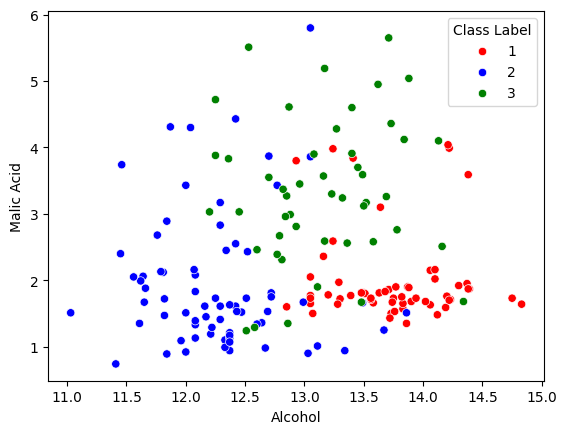

In [25]:
sns.scatterplot(data = df, x = 'Alcohol', y = 'Malic Acid', hue = 'Class Label', palette={1: 'Red', 2:'Blue', 3:'Green'})

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(df.drop('Class Label', axis = 1), df['Class Label'], test_size = 0.3, random_state = 0)

In [17]:
X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((124, 2), (54, 2), (124,), (54,))

In [18]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns = X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns = X_test.columns)

In [20]:
np.round(X_train.describe(), 1)

,Alcohol,Malic Acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.4,1.6
50%,13.0,1.9
75%,13.6,3.2
max,14.8,5.6


In [21]:
np.round(X_train_scaled.describe(), 1)

,Alcohol,Malic Acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


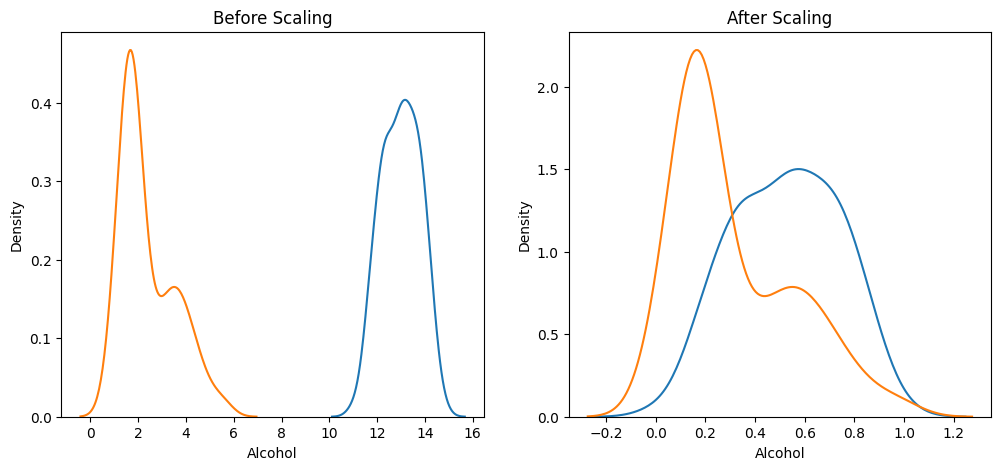

In [24]:
fig, (ax1, ax2) = plt.subplots(ncols = 2, figsize = (12,5))

#Before scaling
ax1.set_title('Before Scaling')
sns.kdeplot(X_train['Alcohol'], ax = ax1)
sns.kdeplot(X_train['Malic Acid'], ax = ax1)

#After Scaling
ax2.set_title('After Scaling')
sns.kdeplot(X_train_scaled['Alcohol'], ax=ax2)
sns.kdeplot(X_train_scaled['Malic Acid'], ax=ax2)
plt.show()